# Telco Customer Churn Analysis

## 1. Project Overview

Customer churn refers to the situation where customers stop using a company's products or services.

The objective of this project is to analyze customer data, identify the factors influencing customer churn, and build machine learning models to predict whether a customer is likely to leave the company.

### Project Objectives
- Analyze customer behavior and identify churn patterns.
- Perform data cleaning and exploratory data analysis (EDA).
- Identify important factors associated with customer churn.
- Apply feature engineering and data preprocessing techniques.
- Build and compare multiple machine learning classification models.
- Evaluate model performance and identify the best-performing model.
- Generate business insights and recommendations to help improve customer retention.

### Problem Type
**Supervised Machine Learning – Binary Classification**

### Target Variable
Churn
- 0 – Customer will not churn.
- 1 – Customer will churn.

Import Libraries

In [48]:
import pandas as pd
import numpy as np

Load Dataset

In [49]:
data = pd.read_csv("Telco_Customer_Churn_Dataset.csv")

Data Understanding

In [50]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [51]:
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [52]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [53]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [54]:
data.duplicated().sum()

np.int64(0)

In [55]:
data = data.drop(columns=["customerID"])

Data Cleaning

In [56]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

In [57]:
data["TotalCharges"] = data["TotalCharges"].fillna(0)

In [58]:
data["TotalCharges"].isnull().sum()

np.int64(0)

Exploratory Data Analysis (EDA)

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

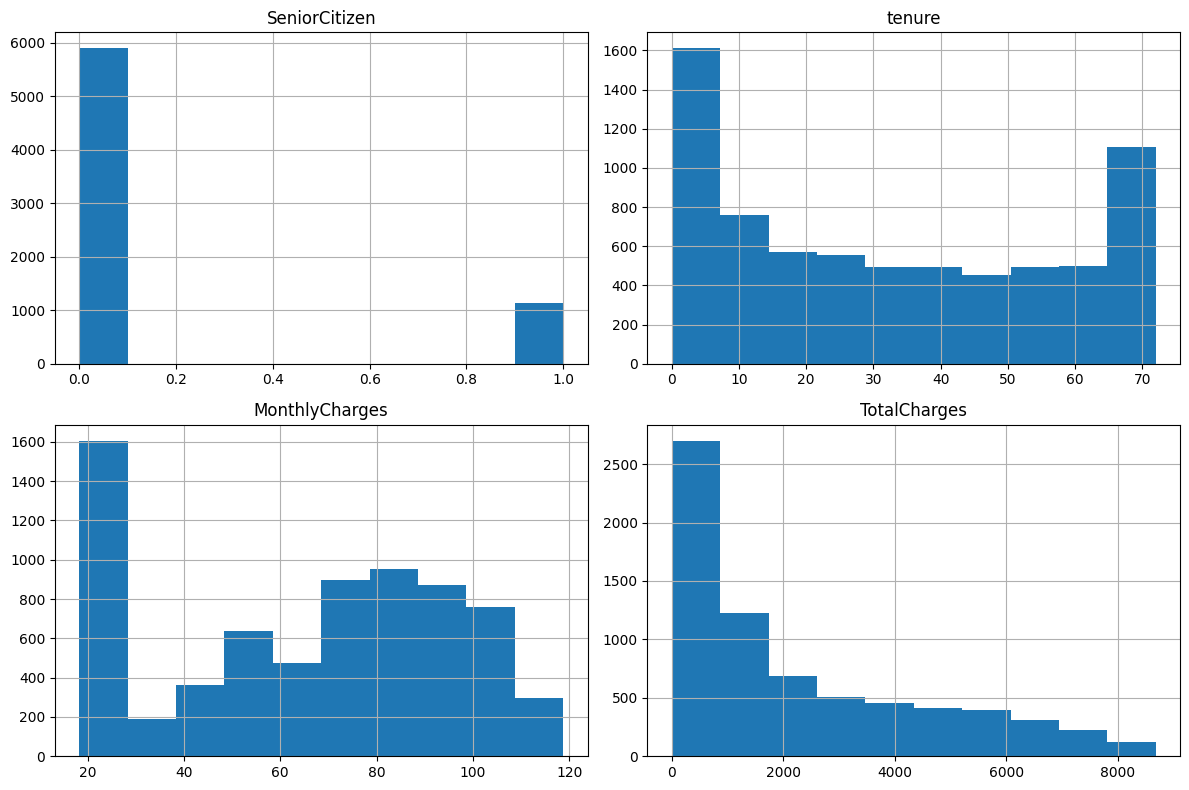

In [60]:
data.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

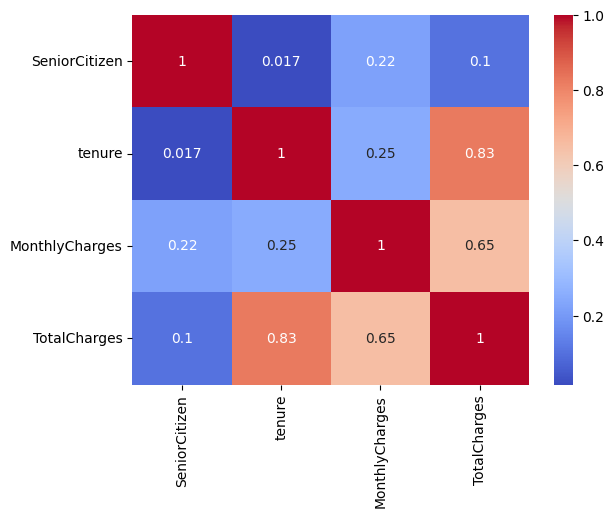

In [61]:
sns.heatmap(
    data.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.show()

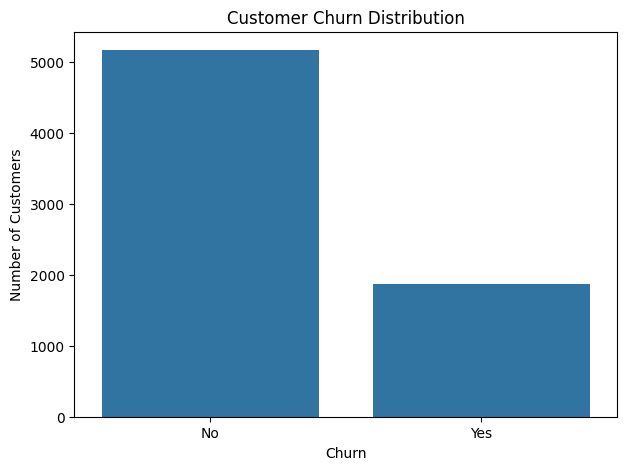

In [62]:
plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

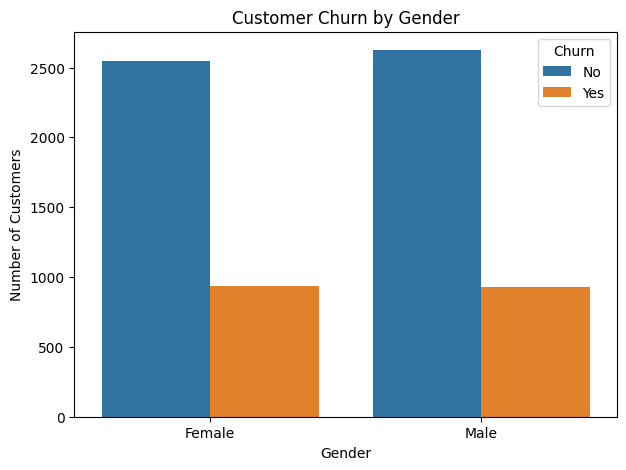

In [63]:
plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="gender", hue="Churn")

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")
plt.show()

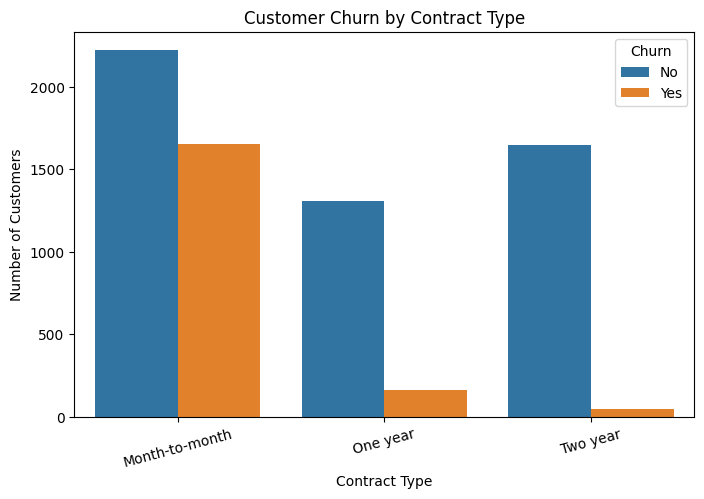

In [64]:
plt.figure(figsize=(8, 5))

sns.countplot(data=data, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.legend(title="Churn")

plt.show()

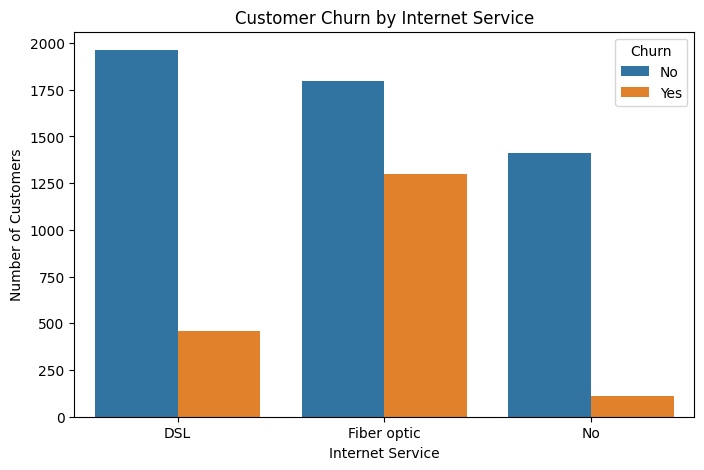

In [65]:
plt.figure(figsize=(8, 5))

sns.countplot(data=data, x="InternetService", hue="Churn")

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")
plt.show()

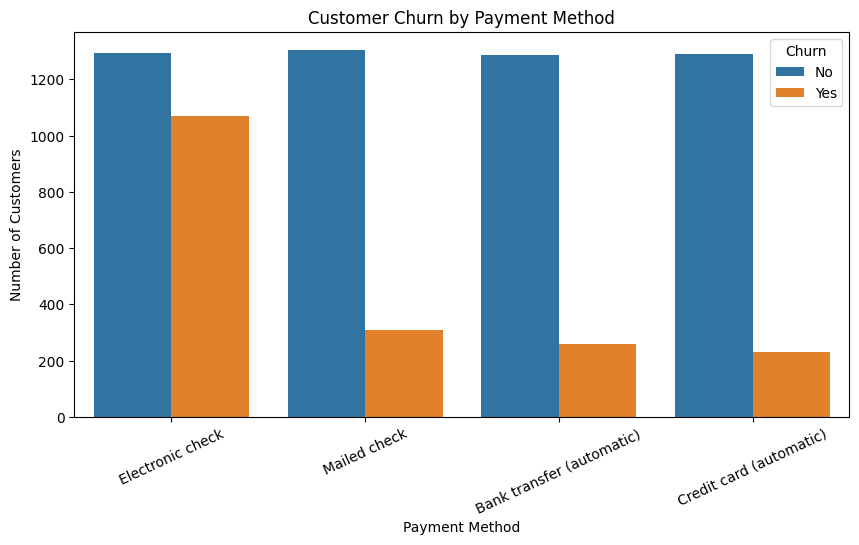

In [66]:
plt.figure(figsize=(10, 5))

sns.countplot(data=data, x="PaymentMethod", hue="Churn")

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=25)
plt.legend(title="Churn")

plt.show()

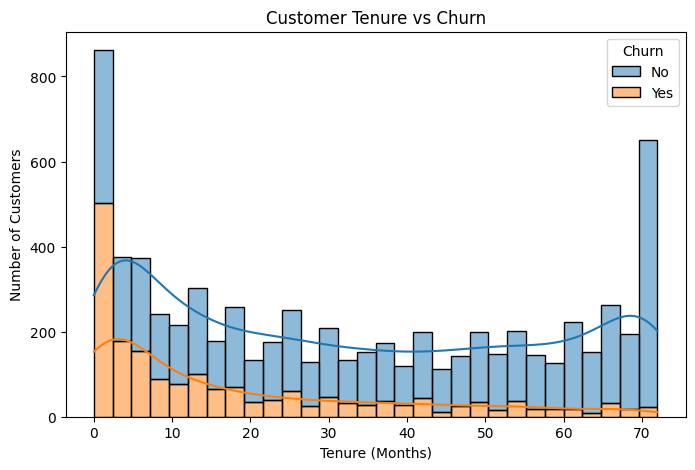

In [67]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [68]:
data["TenureGroup"] = pd.cut(
    data["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

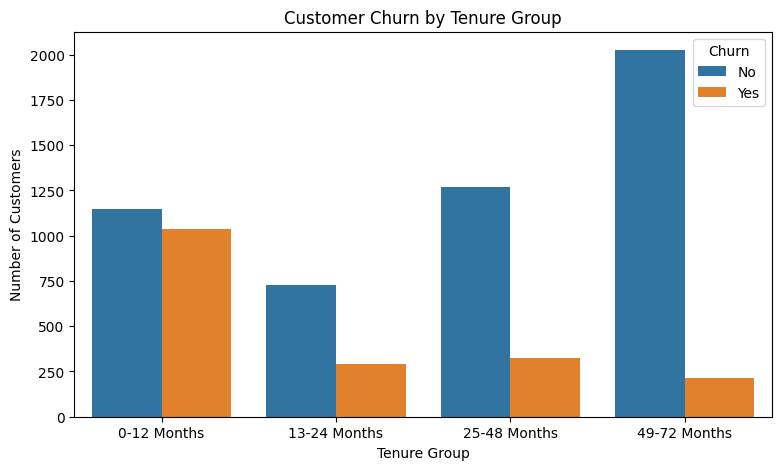

In [69]:
plt.figure(figsize=(9, 5))

sns.countplot(data=data, x="TenureGroup", hue="Churn")

plt.title("Customer Churn by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")
plt.show()

Feature Engineering

In [70]:
data["AverageMonthlyCharges"] = (
    data["TotalCharges"] / data["tenure"].replace(0, 1)
)

In [71]:
data["Churn"] = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

Data Preprocessing

In [72]:
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [73]:
X = data.drop(columns=["Churn"])
y = data["Churn"]

In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 21)
Testing Data: (1409, 21)


In [75]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns

In [76]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Model Building

In [77]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

In [78]:
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    y_proba = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1),
        "Recall": recall_score(y_test, y_pred, pos_label=1),
        "F1 Score": f1_score(y_test, y_pred, pos_label=1),
        "ROC AUC" : roc_auc_score(y_test, y_proba)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
0  Logistic Regression    0.7331     0.4983  0.7914    0.6116   0.8422
3    Gradient Boosting    0.8034     0.6678  0.5160    0.5822   0.8430
2        Random Forest    0.7835     0.6202  0.4759    0.5386   0.8246
1        Decision Tree    0.7260     0.4843  0.4947    0.4894   0.6524


In [79]:
print(results_df.columns)

Index(['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC'], dtype='object')


Model Comparison & Evaluation.

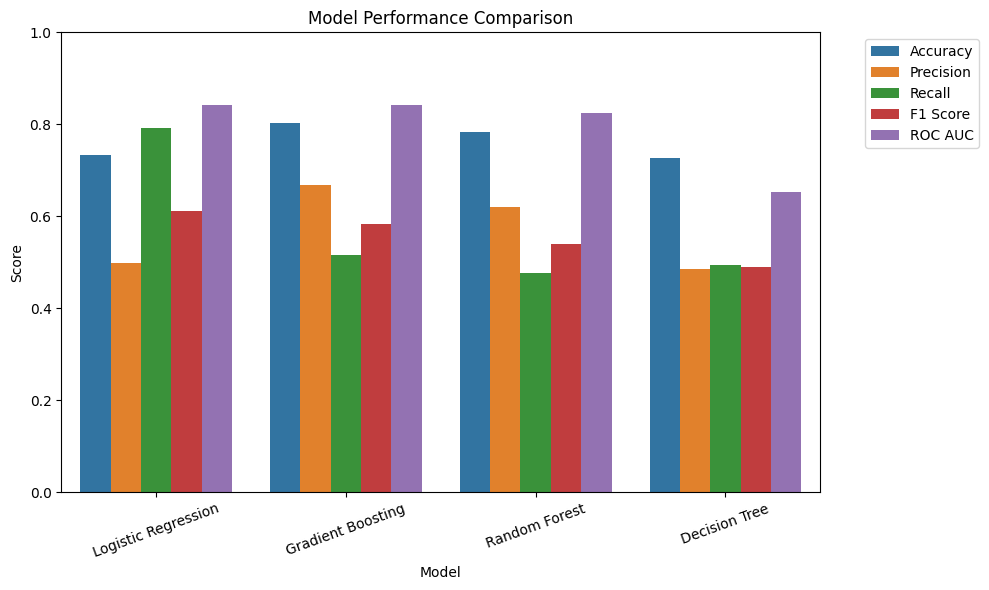

In [80]:
plt.figure(figsize=(10, 6))

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Model Performance Comparison")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [81]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Logistic Regression


Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409

Confusion Matrix:



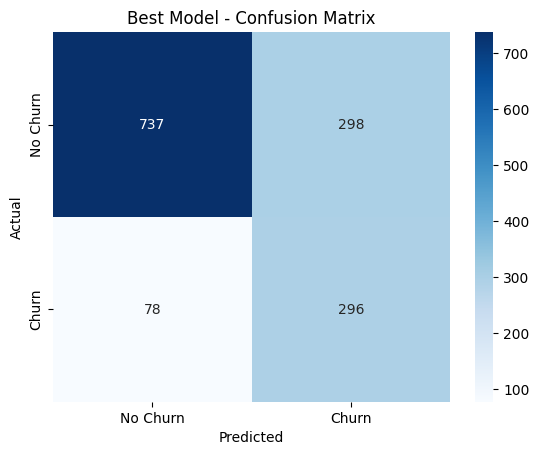

In [82]:
y_pred_best = best_model.predict(X_test)

print("Classification Report:\n")

print(classification_report(y_test, y_pred_best))

print("Confusion Matrix:\n")

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Best Model - Confusion Matrix")

plt.show()

Hyperparameter Tuning

In [83]:
cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

print("Cross Validation Scores:", cv_scores)

print("Average F1 Score:", cv_scores.mean())

Cross Validation Scores: [0.648      0.6391478  0.64064603 0.61776062 0.58990944]
Average F1 Score: 0.627092778805096


In [84]:
for name, model in trained_models.items():

    y_proba = model.predict_proba(X_test)

    print(name)
    print("Classes:", model.classes_)
    print("NaN values:", np.isnan(y_proba).sum())
    print("Probability range:", y_proba.min(), y_proba.max())
    print()

Logistic Regression
Classes: [0 1]
NaN values: 0
Probability range: 0.00852740782684159 0.9914725921731584

Decision Tree
Classes: [0 1]
NaN values: 0
Probability range: 0.0 1.0

Random Forest
Classes: [0 1]
NaN values: 0
Probability range: 0.0 1.0

Gradient Boosting
Classes: [0 1]
NaN values: 0
Probability range: 0.011889976533867454 0.9881100234661325



In [85]:
print(y_test.value_counts())
print(y_test.isnull().sum())

Churn
0    1035
1     374
Name: count, dtype: int64
0


In [86]:
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'classifier__C': 0.01, 'classifier__solver': 'lbfgs'}
Best CV F1 Score: 0.6308538394121903


Final Model Evaluation.

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

ROC-AUC Score: 0.840587460280555


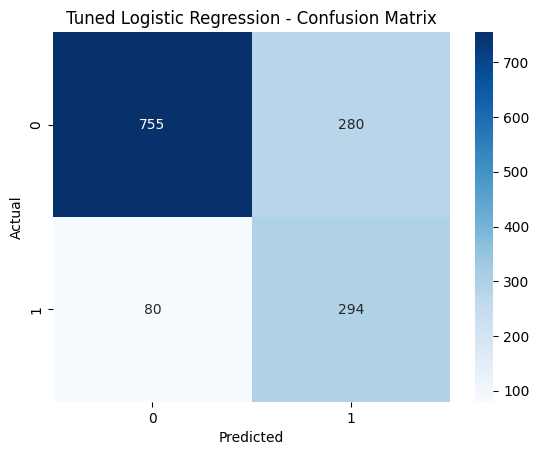

In [87]:
best_lr = grid_search.best_estimator_

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = best_lr.predict(X_test)
y_proba = best_lr.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Logistic Regression - Confusion Matrix")
plt.show()

Business Insights & Recommendations

In [88]:
contract_churn = data.groupby("Contract")["Churn"].agg(
    Total_Customers="count",
    Churned_Customers="sum",
    Churn_Rate="mean"
)

contract_churn["Churn_Rate"] *= 100

print(contract_churn.sort_values(
    by="Churn_Rate",
    ascending=False
).round(2))

                Total_Customers  Churned_Customers  Churn_Rate
Contract                                                      
Month-to-month             3875               1655       42.71
One year                   1473                166       11.27
Two year                   1695                 48        2.83


In [89]:
internet_churn = data.groupby("InternetService")["Churn"].agg(
    Total_Customers="count",
    Churned_Customers="sum",
    Churn_Rate="mean"
)

internet_churn["Churn_Rate"] *= 100

print(internet_churn.sort_values(
    by="Churn_Rate",
    ascending=False
).round(2))

                 Total_Customers  Churned_Customers  Churn_Rate
InternetService                                                
Fiber optic                 3096               1297       41.89
DSL                         2421                459       18.96
No                          1526                113        7.40


In [90]:
payment_churn = data.groupby("PaymentMethod")["Churn"].agg(
    Total_Customers="count",
    Churned_Customers="sum",
    Churn_Rate="mean"
)

payment_churn["Churn_Rate"] *= 100

print(payment_churn.sort_values(
    by="Churn_Rate",
    ascending=False
).round(2))

                           Total_Customers  Churned_Customers  Churn_Rate
PaymentMethod                                                            
Electronic check                      2365               1071       45.29
Mailed check                          1612                308       19.11
Bank transfer (automatic)             1544                258       16.71
Credit card (automatic)               1522                232       15.24


In [91]:
tenure_churn = data.groupby(
    "TenureGroup",
    observed=True
)["Churn"].agg(
    Total_Customers="count",
    Churned_Customers="sum",
    Churn_Rate="mean"
)

tenure_churn["Churn_Rate"] *= 100

print(tenure_churn.round(2))

              Total_Customers  Churned_Customers  Churn_Rate
TenureGroup                                                 
0-12 Months              2186               1037       47.44
13-24 Months             1024                294       28.71
25-48 Months             1594                325       20.39
49-72 Months             2239                213        9.51


In [92]:
churned_customers = data[data["Churn"] == 1]

monthly_revenue_at_risk = churned_customers["MonthlyCharges"].sum()

print(
    "Customers Who Churned:",
    len(churned_customers)
)

print(
    "Estimated Monthly Charges Associated with Churned Customers:",
    round(monthly_revenue_at_risk, 2)
)

Customers Who Churned: 1869
Estimated Monthly Charges Associated with Churned Customers: 139130.85
